In [1]:
import os
os.chdir(r"C:\Users\Rossy Cañari\Downloads\PruebaHavas")

import pandas as pd
from siuba import *

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np

## Read data

In [2]:
Data11 = pd.read_csv("data/raw/raw_data.csv", sep=";")
Data11


,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
0,7/03/2021,230.1,37.8,69.2,22.1
1,14/03/2021,44.5,39.3,45.1,10.4
2,21/03/2021,17.2,45.9,69.3,9.3
3,28/03/2021,151.5,41.3,58.5,18.5
4,4/04/2021,180.8,10.8,58.4,12.9
...,...,...,...,...,...
195,1/12/2024,38.2,3.7,13.8,7.6
196,8/12/2024,94.2,4.9,8.1,9.7
197,15/12/2024,177.0,9.3,6.4,12.8
198,22/12/2024,283.6,42.0,66.2,25.5


Set time variable 

In [3]:
Data11["Week"] = pd.to_datetime(
    Data11["Week"],
    format="%d/%m/%Y",
    errors="coerce"
)


In [4]:
Data12 = (
    Data11
    >> mutate(
        Week = _.Week.astype("datetime64[ns]").dt.strftime('%Y-%m-%d')
    )
    >> mutate(
        Year = _.Week.astype("datetime64[ns]").dt.strftime('%Y')
        , Month = _.Week.astype("datetime64[ns]").dt.strftime('%m')
        , WeekNumber = _.Week.astype("datetime64[ns]").dt.isocalendar().week.astype("string").str.zfill(2)
    )
)
Data12

,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber
0,2021-03-07,230.1,37.8,69.2,22.1,2021,03,09
1,2021-03-14,44.5,39.3,45.1,10.4,2021,03,10
2,2021-03-21,17.2,45.9,69.3,9.3,2021,03,11
3,2021-03-28,151.5,41.3,58.5,18.5,2021,03,12
4,2021-04-04,180.8,10.8,58.4,12.9,2021,04,13
...,...,...,...,...,...,...,...,...
195,2024-12-01,38.2,3.7,13.8,7.6,2024,12,48
196,2024-12-08,94.2,4.9,8.1,9.7,2024,12,49
197,2024-12-15,177.0,9.3,6.4,12.8,2024,12,50
198,2024-12-22,283.6,42.0,66.2,25.5,2024,12,51


In [5]:
Data12.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Week               200 non-null    object 
 1   Spend Channel 1    200 non-null    float64
 2   Spend Channel 2    200 non-null    float64
 3   Spend Competitors  200 non-null    float64
 4   Conversions        200 non-null    float64
 5   Year               200 non-null    object 
 6   Month              200 non-null    object 
 7   WeekNumber         200 non-null    string 
dtypes: float64(4), object(3), string(1)
memory usage: 12.6+ KB


In [6]:
DataCuanti11 = Data12.select_dtypes(include=["int", "float"])
DataCuanti11


,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [7]:
DataCuanti11.describe()


,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


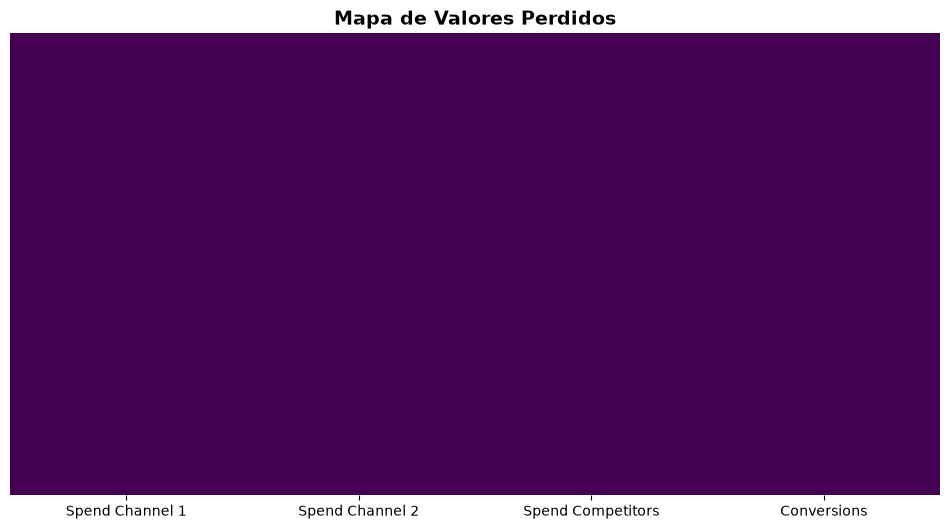

In [8]:
# Se muestra mapa de valores perdidos
plt.figure(figsize=(12, 6))
sns.heatmap(DataCuanti11.isna(), cmap="viridis", cbar=False, yticklabels=False)
plt.title("Mapa de Valores Perdidos", fontsize=14, fontweight='bold')
plt.show()


It hasn't been found missing data to treat

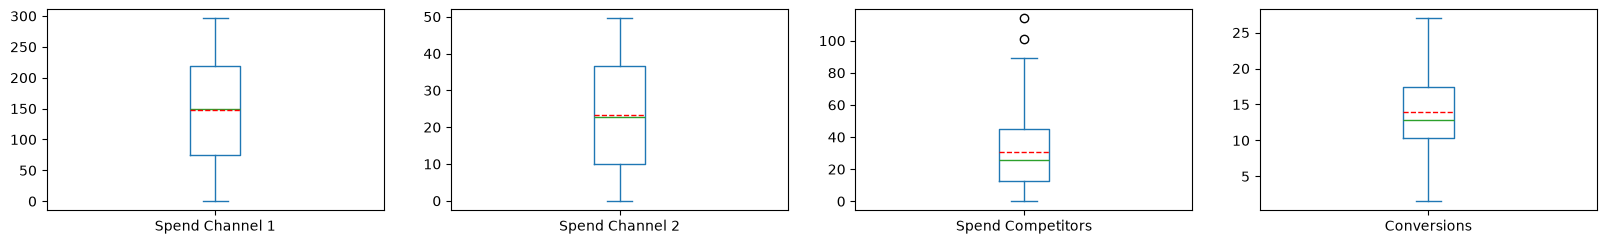

In [9]:
# Otra forma
DataCuanti11.plot(kind ="box", subplots=True, layout = (4, 4), figsize=(20, 12), sharex = False
                  , showmeans = True
                  , meanline = True
                  , meanprops={"color": "red", "linewidth": 1}
                  )
plt.show()

### Spend Channel 1

Weekly investment in Channel 1 ranges from approximately 0 to 300, with a median close to 150. The middle 50% of observations fall between approximately 75 and 220.

The distribution appears broadly symmetric, with no apparent outliers under the boxplot rule. This channel has the largest absolute investment range.

### Spend Channel 2

Weekly investment in Channel 2 ranges from approximately 0 to 50, with a median near 23. The middle 50% of observations fall between approximately 10 and 37.

The distribution also appears broadly symmetric, with no apparent outliers. If both channels use the same monetary units, investment in Channel 2 is generally lower than in Channel 1.

### Spend Competitors

Estimated weekly competitor investment has a median of approximately 25, with the middle 50% of observations between approximately 12 and 45.

The longer upper whisker and two high observations near 100 and 115 suggest a right-skewed distribution. These observations may represent weeks of unusually high competitor spending. They should be investigated rather than automatically removed, since they could reflect genuine marketing activity.

### Conversions

Weekly conversions have a median of approximately 13, with the middle 50% of observations between approximately 10 and 17. The observed values range from approximately 1 to 27.

The distribution appears slightly right-skewed, with no apparent outliers under the boxplot rule. These values describe weekly conversions, not monthly totals.


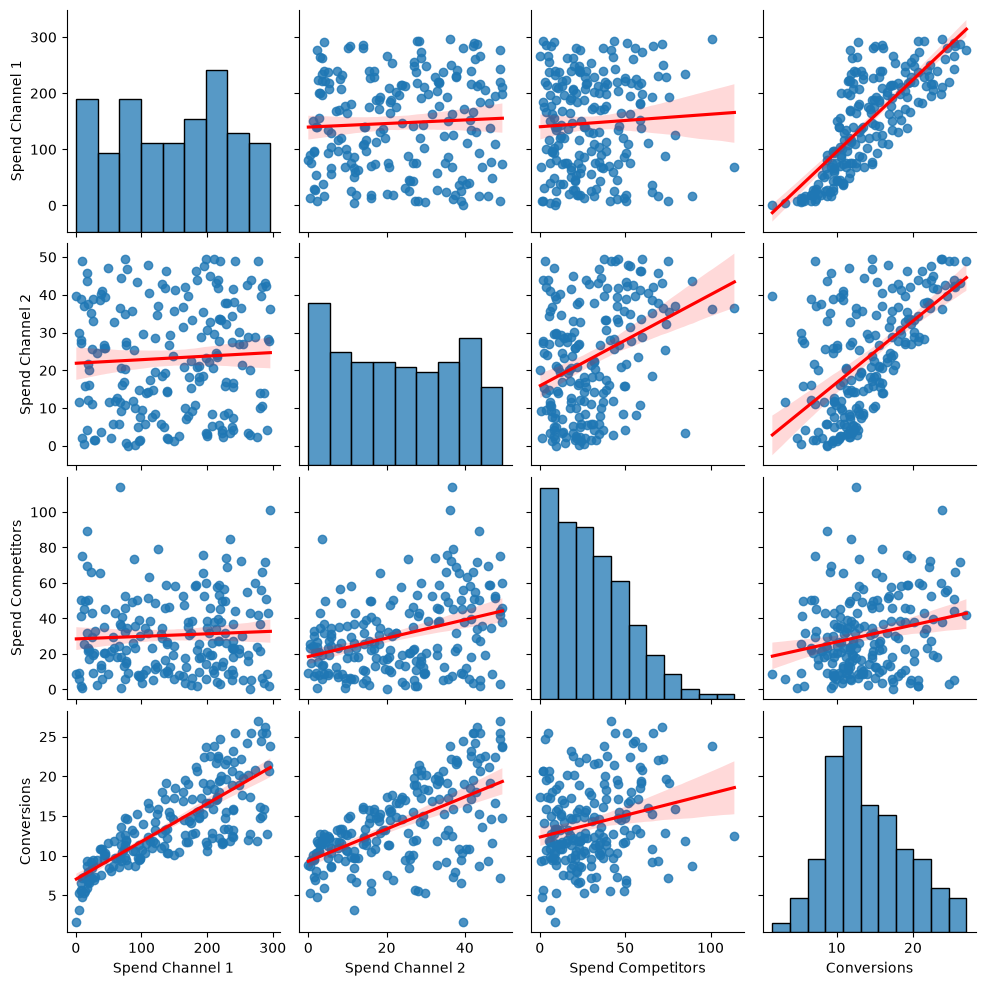

In [10]:
sns.pairplot(DataCuanti11
             , kind = 'reg'
             , plot_kws = {'line_kws': {'color': 'red'}}
             );


The pairplot displays the distributions of the variables on the diagonal and their pairwise relationships in the remaining panels. The red lines summarize the linear trends.

### Relationships Between Predictors

Channel 1 investment shows little apparent linear association with either Channel 2 investment or competitor spending.

Channel 2 investment and competitor spending show a positive association. This relationship may partly explain why competitor spending appears positively associated with conversions in the pairplot but is not statistically significant in the multiple regression model.

The pairplot shows unadjusted relationships, whereas each multiple regression coefficient describes an association conditional on the other predictors.


## Asimetría y Curtosis

In [11]:
# Librerias
from scipy.stats import skew, skewtest, norm
from scipy.stats import kurtosis

# Cálculo de la asimetria y curtosis para cada variable
for i in DataCuanti11.columns:
    val_asimetria = DataCuanti11[i].skew()
    val_curtosis = kurtosis(DataCuanti11[i],fisher = False)

    print(f'''Para la variable {i}, la asimetria es: {val_asimetria.round(2)} y la curtosis es: {val_curtosis.round(2)}\n''')


Para la variable Spend Channel 1, la asimetria es: -0.07 y la curtosis es: 1.77

Para la variable Spend Channel 2, la asimetria es: 0.09 y la curtosis es: 1.74

Para la variable Spend Competitors, la asimetria es: 0.89 y la curtosis es: 3.6

Para la variable Conversions, la asimetria es: 0.41 y la curtosis es: 2.57



### Skewness and Kurtosis

Skewness describes distributional asymmetry: values near zero indicate approximate symmetry, positive values indicate a longer right tail, and negative values indicate a longer left tail.

The calculation uses Pearson kurtosis (`fisher=False`), for which the normal distribution has a kurtosis of 3. Values below 3 indicate a platykurtic distribution, while values above 3 indicate a leptokurtic distribution.

| Variable | Skewness | Kurtosis | Interpretation |
|---|---:|---:|---|
| Spend Channel 1 | -0.07 | 1.77 | Approximately symmetric and platykurtic, with less pronounced tails than a normal distribution. |
| Spend Channel 2 | 0.09 | 1.74 | Approximately symmetric and platykurtic, with less pronounced tails than a normal distribution. |
| Spend Competitors | 0.89 | 3.60 | Positively skewed and leptokurtic, consistent with occasional unusually high weekly investments. |
| Conversions | 0.41 | 2.57 | Mildly right-skewed and slightly platykurtic, with some weeks showing relatively high conversion values. |

Competitor spending exhibits the greatest asymmetry and the highest kurtosis. This is consistent with the earlier plots, which showed a concentration of observations at lower spending levels and a few high values.

These descriptive statistics alone do not establish whether a variable follows a normal distribution.


In [12]:
# Z-score
for i in DataCuanti11.columns:
    z_scores = np.abs((DataCuanti11[i] - DataCuanti11[i].mean()) / DataCuanti11[i].std())
    outliers = DataCuanti11[z_scores > 2.5]

    print(f'''La variable {i} tiene: {outliers.shape[0]} valores outliers\n''')



La variable Spend Channel 1 tiene: 0 valores outliers

La variable Spend Channel 2 tiene: 0 valores outliers

La variable Spend Competitors tiene: 3 valores outliers

La variable Conversions tiene: 0 valores outliers



### Potential Outliers Based on Z-Scores


| Variable | Observations flagged |
|---|---:|
| Spend Channel 1 | 0 |
| Spend Channel 2 | 0 |
| Spend Competitors | 3 |
| Conversions | 0 |

Three observations of competitor spending lie more than 2.5 standard deviations from its mean. These are potential outliers under the chosen rule, not confirmed data errors.

The earlier boxplot showed two potential outliers because it uses a different criterion, typically based on 1.5 times the interquartile range. Different detection rules can flag different observations.


## Variables cualitativas

In [13]:
DataCuali11 = Data12.select_dtypes(exclude=["int", "float"])
DataCuali11


,Week,Year,Month,WeekNumber
0,2021-03-07,2021,03,09
1,2021-03-14,2021,03,10
2,2021-03-21,2021,03,11
3,2021-03-28,2021,03,12
4,2021-04-04,2021,04,13
...,...,...,...,...
195,2024-12-01,2024,12,48
196,2024-12-08,2024,12,49
197,2024-12-15,2024,12,50
198,2024-12-22,2024,12,51


In [ ]:
DataCuali12 = (
    DataCuali11
    >> select(-_.Week)
)
DataCuali12

,Year,Month,WeekNumber
0,2021,03,09
1,2021,03,10
2,2021,03,11
3,2021,03,12
4,2021,04,13
...,...,...,...
195,2024,12,48
196,2024,12,49
197,2024,12,50
198,2024,12,51



Distribución de la variable 'Year':
    Year  total  PorTotal
2  2023     53      26.5
1  2022     52      26.0
3  2024     52      26.0
0  2021     43      21.5


c:\Users\Rossy Cañari\Downloads\PruebaHavas\.venv\Lib\site-packages\siuba\dply\verbs.py:561: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = __data.apply(df_summarize, *args, **kwargs)


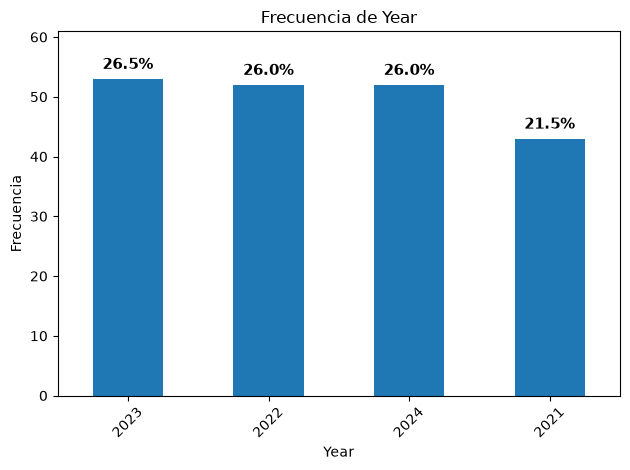


Distribución de la variable 'Month':
    Month  total  PorTotal
9     10     19       9.5
4     05     18       9.0
6     07     18       9.0
11    12     18       9.0
2     03     17       8.5
3     04     17       8.5
5     06     17       8.5
7     08     17       8.5
8     09     17       8.5
10    11     16       8.0
0     01     14       7.0
1     02     12       6.0


c:\Users\Rossy Cañari\Downloads\PruebaHavas\.venv\Lib\site-packages\siuba\dply\verbs.py:561: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = __data.apply(df_summarize, *args, **kwargs)


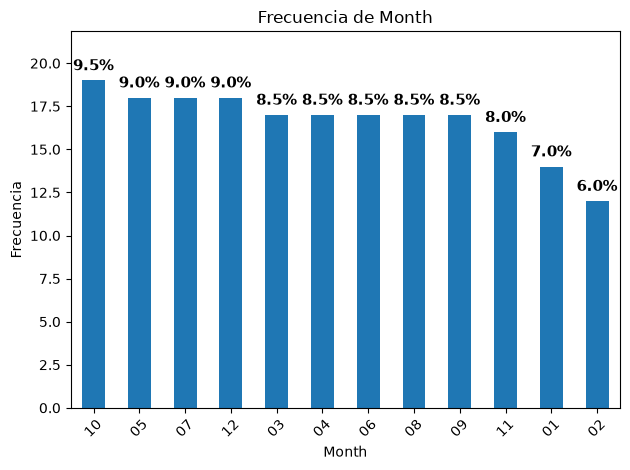

c:\Users\Rossy Cañari\Downloads\PruebaHavas\.venv\Lib\site-packages\siuba\dply\verbs.py:561: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = __data.apply(df_summarize, *args, **kwargs)



Distribución de la variable 'WeekNumber':
    WeekNumber  total  PorTotal
8          09      4       2.0
9          10      4       2.0
10         11      4       2.0
11         12      4       2.0
12         13      4       2.0
13         14      4       2.0
14         15      4       2.0
15         16      4       2.0
16         17      4       2.0
17         18      4       2.0
18         19      4       2.0
19         20      4       2.0
20         21      4       2.0
21         22      4       2.0
22         23      4       2.0
23         24      4       2.0
24         25      4       2.0
25         26      4       2.0
26         27      4       2.0
27         28      4       2.0
28         29      4       2.0
29         30      4       2.0
30         31      4       2.0
31         32      4       2.0
32         33      4       2.0
33         34      4       2.0
34         35      4       2.0
35         36      4       2.0
36         37      4       2.0
37         38      4      

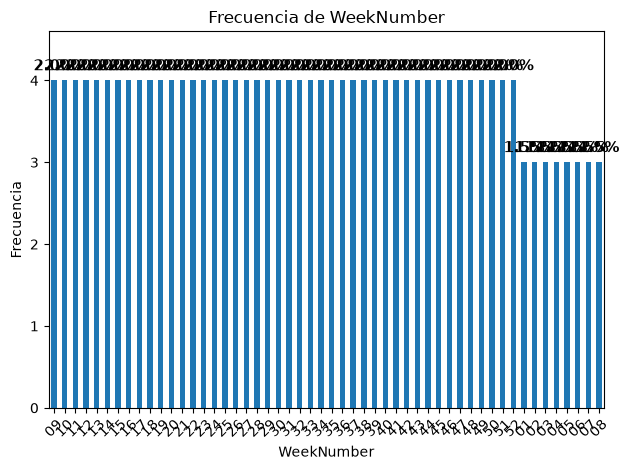

In [15]:
# Otra forma (Agregando etiquetas)
for i in DataCuali12.columns:
    resultado = (
        DataCuali12
        >> mutate(var_nueva = if_else(_[i].isna(), "NA", _[i]))
        >> group_by(_.var_nueva)
        >> summarize(total = _.shape[0])
        >> ungroup()
        >> mutate(PorTotal = (_.total / _.total.sum())*100)
        >> arrange(-_.total)
    )
    
    resultado1 = resultado.rename(columns={'var_nueva': f'''{i}'''})

    print(f"\nDistribución de la variable '{i}':\n", resultado1)
    
    # Graficar
    ax = resultado1.set_index(i).plot(kind='bar', y="total", title=f'Frecuencia de {i}', legend=False)
    plt.ylabel('Frecuencia')
    plt.xlabel(i)
    plt.xticks(rotation=45)

    # Aumentar límite del eje Y para que entren las etiquetas
    max_total = resultado1["total"].max()
    plt.ylim(0, max_total * 1.15)  # Ajusta este valor si necesitas más espacio

    # Agregar etiquetas con PorTotal
    for idx, val in enumerate(resultado1["PorTotal"]):
        total = resultado1["total"].iloc[idx]
        ax.text(
            idx,
            total + max_total * 0.02,
            f'{val:.1f}%',
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()



## Unir data

In [19]:
DataAnalisis11 = pd.concat([DataCuanti11, DataCuali12], axis=1)
DataAnalisis11


,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber
0,230.1,37.8,69.2,22.1,2021,03,09
1,44.5,39.3,45.1,10.4,2021,03,10
2,17.2,45.9,69.3,9.3,2021,03,11
3,151.5,41.3,58.5,18.5,2021,03,12
4,180.8,10.8,58.4,12.9,2021,04,13
...,...,...,...,...,...,...,...
195,38.2,3.7,13.8,7.6,2024,12,48
196,94.2,4.9,8.1,9.7,2024,12,49
197,177.0,9.3,6.4,12.8,2024,12,50
198,283.6,42.0,66.2,25.5,2024,12,51


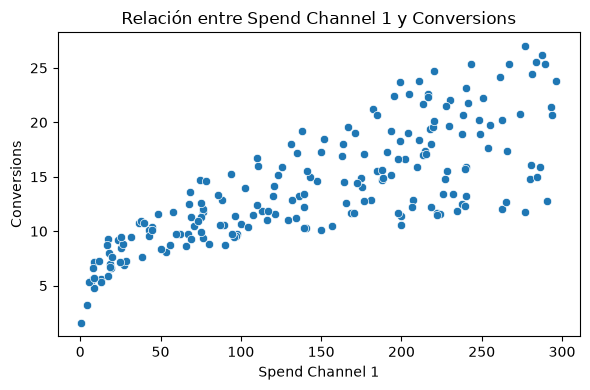

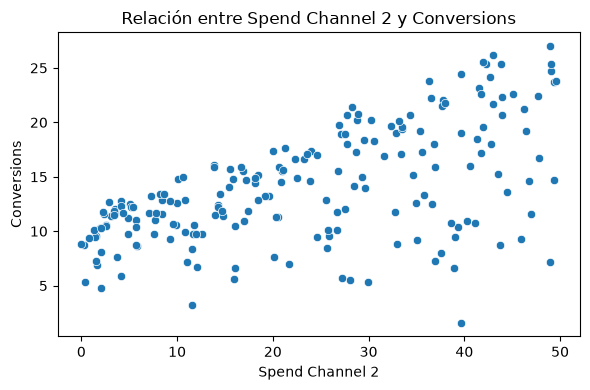

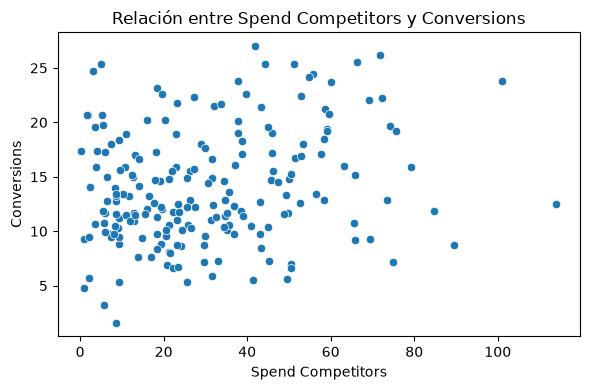

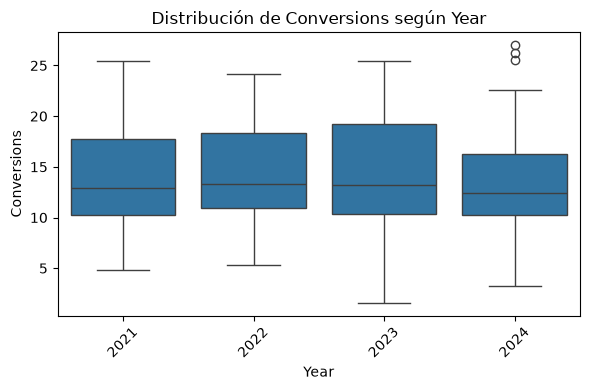

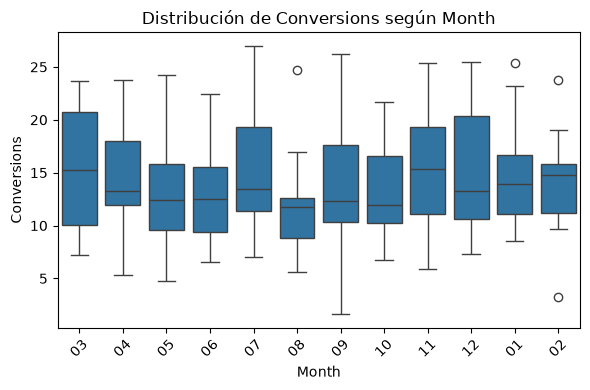

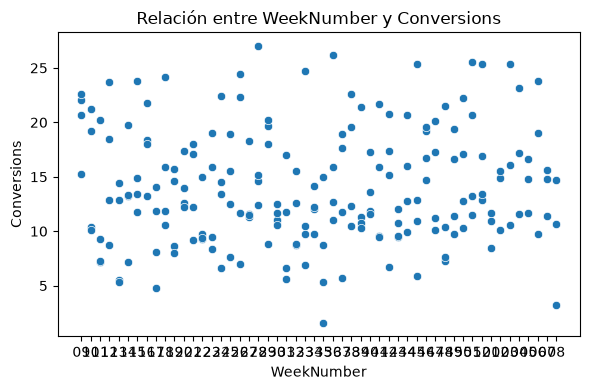

In [20]:
# Crear una lista de variables, quitando de allí la variable dependiente
lst_vars1 = DataAnalisis11.columns.values.tolist()
var_target = "Conversions"

lst_vars1.remove(var_target)

# Graficar
for i in lst_vars1:
    if pd.api.types.is_object_dtype(DataAnalisis11[i]):
        # Boxplot: variable categórica vs variable cuantitativa (target)
        plt.figure(figsize=(6, 4))
        sns.boxplot(data=DataAnalisis11, x=i, y=var_target)
        plt.title(f'Distribución de {var_target} según {i}')
        plt.xticks(rotation=45)
    else:
        # Scatter plot: ambas variables numéricas
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=DataAnalisis11, x=i, y=var_target)
        plt.title(f'Relación entre {i} y {var_target}')
    
    plt.tight_layout()
    plt.show()


## Codificiación

In [27]:
DataAnalisis12 = (
    DataAnalisis11
    >> mutate(
        YEAR = case_when({
            _.Year == "2021": 1
            , _.Year == "2022": 2
            , _.Year == "2023": 3
            , _.Year == "2024": 4
        })
    )
    >> mutate(
        MONTH = _.Month.astype("int64")
        , WN = _.WeekNumber.astype("int64")
    )
    >> rename(
        SpendChannel1 = "Spend Channel 1"
        , SpendChannel2 = "Spend Channel 2"
        , SpendCompetitors = "Spend Competitors"
    )
    >> select(
        -_.Year, -_.Month, -_.WeekNumber
    )
)
DataAnalisis12


,SpendChannel1,SpendChannel2,SpendCompetitors,Conversions,YEAR,MONTH,WN
0,230.1,37.8,69.2,22.1,1,3,9
1,44.5,39.3,45.1,10.4,1,3,10
2,17.2,45.9,69.3,9.3,1,3,11
3,151.5,41.3,58.5,18.5,1,3,12
4,180.8,10.8,58.4,12.9,1,4,13
...,...,...,...,...,...,...,...
195,38.2,3.7,13.8,7.6,4,12,48
196,94.2,4.9,8.1,9.7,4,12,49
197,177.0,9.3,6.4,12.8,4,12,50
198,283.6,42.0,66.2,25.5,4,12,51


In [28]:
DataAnalisis12.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SpendChannel1     200 non-null    float64
 1   SpendChannel2     200 non-null    float64
 2   SpendCompetitors  200 non-null    float64
 3   Conversions       200 non-null    float64
 4   YEAR              200 non-null    int64  
 5   MONTH             200 non-null    int64  
 6   WN                200 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 11.1 KB


In [29]:
# Primero seleccionar la columna target y ponerlo al final
list_variable1 = DataAnalisis12.columns.values.tolist()
var_target = "Conversions"

list_variable1.remove(var_target)
list_variable1.append(var_target)

# Seleccionar las variables en ese orden
DataAnalisis12 = (
    DataAnalisis12
    >> select(*list_variable1)
)
DataAnalisis12


,SpendChannel1,SpendChannel2,SpendCompetitors,YEAR,MONTH,WN,Conversions
0,230.1,37.8,69.2,1,3,9,22.1
1,44.5,39.3,45.1,1,3,10,10.4
2,17.2,45.9,69.3,1,3,11,9.3
3,151.5,41.3,58.5,1,3,12,18.5
4,180.8,10.8,58.4,1,4,13,12.9
...,...,...,...,...,...,...,...
195,38.2,3.7,13.8,4,12,48,7.6
196,94.2,4.9,8.1,4,12,49,9.7
197,177.0,9.3,6.4,4,12,50,12.8
198,283.6,42.0,66.2,4,12,51,25.5


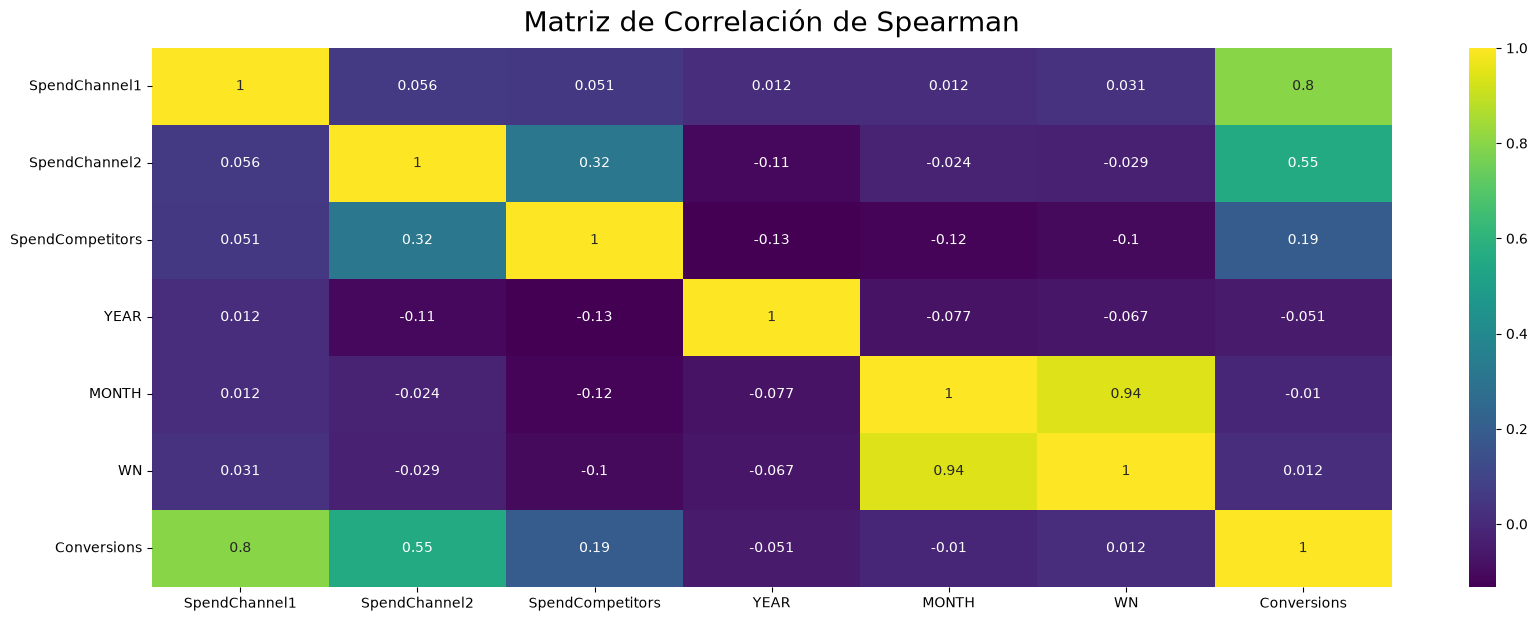

In [30]:
# Coeficiente de correlación de Spearman
MatCorr = DataAnalisis12.corr(method="spearman")
MatCorr


# Mapa de calor de la matriz de correlaciones
plt.figure(figsize=(20, 7))
heatmap = sns.heatmap(data=MatCorr,cmap='viridis',annot=True)
heatmap.set_title('Matriz de Correlación de Spearman', fontdict={'fontsize':20}, pad=12);


### Relationships with Weekly Conversions

Channel 1 has the strongest pairwise monotonic association with conversions, followed by Channel 2. These results support considering both marketing investments as predictors, but they do not establish causal effects or measure their importance after controlling for other variables.

The weak positive correlation between competitor spending and conversions does not imply that competitor activity increases conversions. It may partly reflect its association with Channel 2 spending or other shared factors.

### Relationships Between Predictors

**Month and Week Number are very strongly correlated ($\rho_s = 0.94$).** Both describe the position within the year and therefore contain overlapping information. Including both in a regression may introduce multicollinearity, making their individual coefficients less precise. The variance inflation factor (VIF) can help assess this concern in the actual regression design.

**Channel 2 and competitor spending have a positive correlation of 0.32.** This indicates some tendency for their investments to rise together, although this correlation alone does not indicate severe multicollinearity.

**Channel 1 has very weak correlations with the other predictors**, including Channel 2 ($0.056$) and competitor spending ($0.051$).


## Save information

In [32]:
DataAnalisis12.to_csv("data/processed/data_general_eval.csv", encoding="utf-8", index=False)
